# Exploratory data analysis of the Natural Scenes Dataset (NSD)

**Role:** Data scientist · **Paper:** Ferrante, Boccato, Toschi & VanRullen (2025), *Evidence for compositionality in fMRI visual representations via Brain Algebra*, Communications Biology 8:1263.

| Part | Content | Data |
|---|---|---|
| **1** | Experiment design and stimuli | `nsd_stim_info_merged.csv` |
| **2** | Image content: COCO captions and object categories | COCO 2017 annotations |
| **3** | The fMRI data: mask and betas | subject 1, sessions 1–5 |

Every code cell starts with an ID such as `# [2.5.3]`: part, section, cell. Each part starts with its own setup cell, so a part can be re-run on its own.

# Part 1 — Experiment design and stimuli (NSD)

This part does not touch the fMRI signal yet. It answers the basic questions about the experiment:

1. How many images are in the Natural Scenes Dataset (NSD) and what do we know about each one?
2. How are the images divided among the 8 subjects?
3. When did subject 1 see each image (trial → session)?
4. How many repetitions does each image have?
5. How is the train / test split of the paper defined?
6. How far apart are the repetitions of the same image?
7. Do the four subjects used in the paper have the same design?

Source: `nsd_stim_info_merged.csv`, one row per image.

In [1]:
# [1.0.1] Imports, paths and a common chart style
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go

DATA = Path("..")            # project folder, where the NSD files are
TRIALS_PER_SESSION = 750     # every scanning session has 750 trials
N_SESSIONS_USED = 37         # sessions loaded by the Brain-Diffuser code; they reproduce the paper's numbers

import plotly.io as pio

# Each chart is saved twice: interactive (Jupyter, VS Code) and as a static image (shown on GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 1.5
pio.defaults.default_width = 1000
pio.defaults.default_height = 500

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
BLUE_RAMP = ["#86b6ef", "#2a78d6", "#104281"]   # light to dark, for ordered categories


def style(fig, title, xaxis_title=None, yaxis_title=None):
    fig.update_layout(
        title=title,
        paper_bgcolor=SURFACE,
        plot_bgcolor=SURFACE,
        font=dict(family="system-ui, 'Segoe UI', sans-serif", color=INK),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
        margin=dict(t=90),
    )
    fig.update_xaxes(showgrid=False, linecolor=GRID, tickfont_color=MUTED)
    fig.update_yaxes(gridcolor=GRID, zeroline=False, tickfont_color=MUTED)
    # Axis titles are set only when given, so charts with several panels keep their own
    if xaxis_title is not None:
        fig.update_xaxes(title_text=xaxis_title)
    if yaxis_title is not None:
        fig.update_yaxes(title_text=yaxis_title)
    return fig

## 1. Loading the stimulus table

Each row is one image. The important columns:

| Column | Meaning |
|---|---|
| `nsdId` | image ID inside NSD (0 … 72,999) |
| `cocoId` | ID of the same image in the COCO dataset |
| `cocoSplit` | which part of COCO it comes from (this is **not** the train/test split of the paper) |
| `shared1000` | `True` if the image was seen by all 8 subjects |
| `subjectN` | 1 if the image belongs to subject N's set |
| `subjectN_rep0/1/2` | the trial number at which subject N saw the image for the 1st / 2nd / 3rd time; 0 = never shown |

In [2]:
# [1.1.1] Load the table and look at the first rows
stim = pd.read_csv(DATA / "nsd_stim_info_merged.csv", index_col=0)
print("Shape (rows, columns):", stim.shape)

stim[["nsdId", "cocoId", "cocoSplit", "shared1000",
      "subject1", "subject1_rep0", "subject1_rep1", "subject1_rep2"]].head()

Shape (rows, columns): (73000, 40)


,nsdId,cocoId,cocoSplit,shared1000,subject1,subject1_rep0,subject1_rep1,subject1_rep2
0,0,532481,val2017,False,0,0,0,0
1,1,245764,val2017,False,0,0,0,0
2,2,385029,val2017,False,0,0,0,0
3,3,311303,val2017,False,0,0,0,0
4,4,393226,val2017,False,0,0,0,0


## 2. How the 73,000 images are divided among subjects

The rule of the experiment: each subject has 10,000 images, of which 1,000 are common to everybody (`shared1000`) and 9,000 are seen only by that subject.

We check the rule on the data.

In [3]:
# [1.2.1] Images per subject: shared and unique
subject_cols = [f"subject{s}" for s in range(1, 9)]

rows = []
for col in subject_cols:
    in_set = stim[col] == 1
    rows.append({
        "subject": col,
        "images in set": int(in_set.sum()),
        "shared (shared1000)": int((in_set & stim["shared1000"]).sum()),
        "unique": int((in_set & ~stim["shared1000"]).sum()),
    })

pd.DataFrame(rows).set_index("subject")

,images in set,shared (shared1000),unique
subject,,,
subject1,10000,1000,9000
subject2,10000,1000,9000
subject3,10000,1000,9000
subject4,10000,1000,9000
subject5,10000,1000,9000
subject6,10000,1000,9000
subject7,10000,1000,9000
subject8,10000,1000,9000


## 3. From trial to session (subject 1)

The columns `subject1_rep0/1/2` say **at which trial** the image was shown. Trials are numbered from 1 and a session has 750 trials, so:

$$\text{session} = \left\lfloor \frac{\text{trial} - 1}{750} \right\rfloor + 1$$

Examples: trial 750 → session 1; trial 751 → session 2; trial 13,792 → session 19.

We reshape the table from "wide" (one image per row, three repetition columns) to "long" (**one trial per row**). This is the design table of subject 1 and the link to the brain data: the row with `trial = t` corresponds to brain response number `t`.

In [4]:
# [1.3.1] Build the trial table of subject 1
rep_cols = ["subject1_rep0", "subject1_rep1", "subject1_rep2"]

trials = (
    stim.loc[stim["subject1"] == 1, ["nsdId", "cocoId", "shared1000"] + rep_cols]
        .melt(id_vars=["nsdId", "cocoId", "shared1000"],
              value_vars=rep_cols, var_name="rep", value_name="trial")
)

# rep: "subject1_rep0" -> 1 (first viewing), ... "subject1_rep2" -> 3
trials["rep"] = trials["rep"].str[-1].astype(int) + 1

# 0 means "never shown", not trial number 0
trials = trials[trials["trial"] > 0]

trials["session"] = (trials["trial"] - 1) // TRIALS_PER_SESSION + 1
trials = trials.sort_values("trial").reset_index(drop=True)

print("Number of trials:", len(trials))
trials.head(8)

Number of trials: 30000


,nsdId,cocoId,shared1000,rep,trial,session
0,46002,412922,True,1,1,1
1,61882,474858,False,1,2,1
2,828,320696,False,1,3,1
3,67573,234676,False,1,4,1
4,16020,301595,False,1,5,1
5,40422,129059,False,1,6,1
6,51517,172751,False,1,7,1
7,62325,481427,False,1,8,1


### What kind of trials each session contains

All sessions have 750 trials, but their composition changes: at the beginning almost all images are new, towards the end almost all are repetitions.

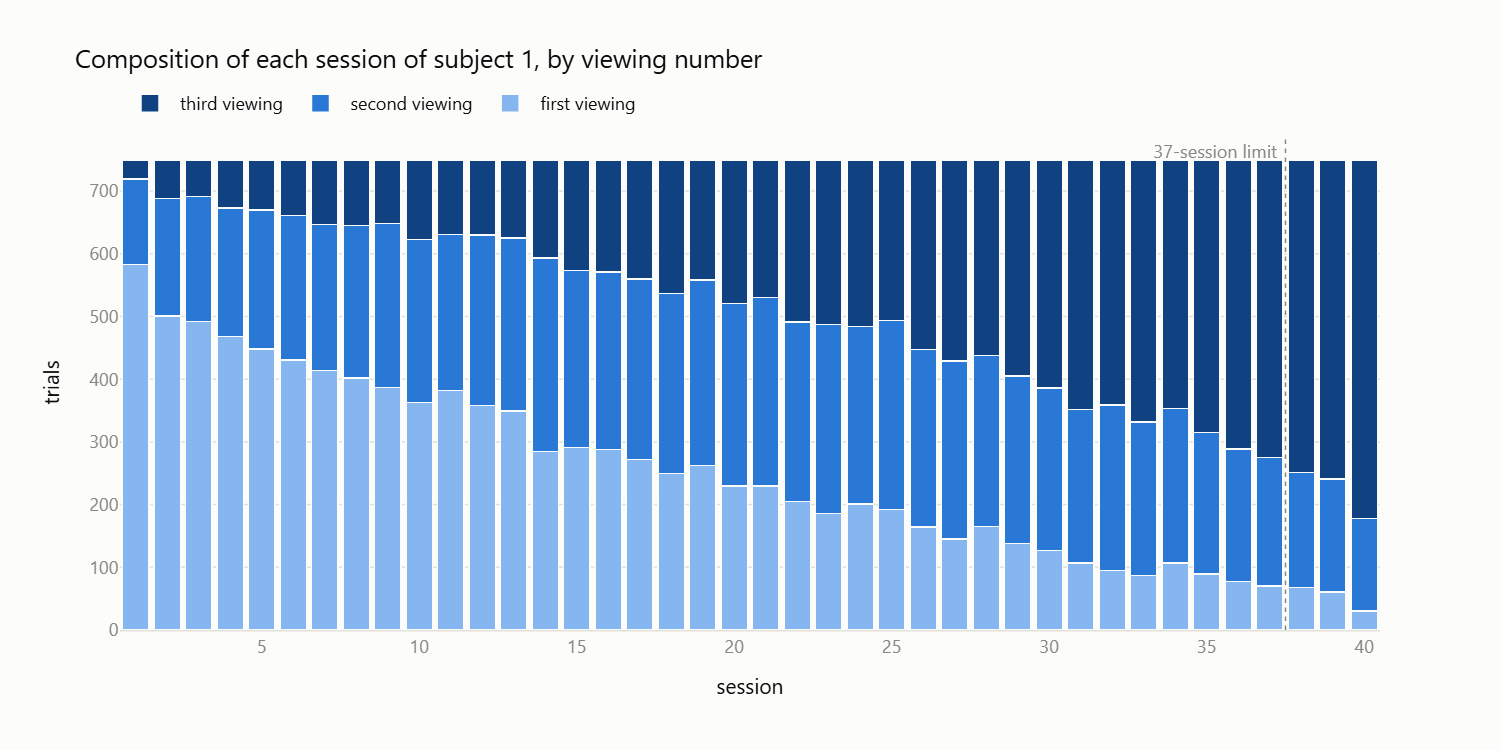

In [5]:
# [1.3.3] Chart: composition of each session
composition = trials.groupby(["session", "rep"]).size().unstack("rep", fill_value=0)

labels = {1: "first viewing", 2: "second viewing", 3: "third viewing"}

fig = go.Figure()
for rep, color in zip([1, 2, 3], BLUE_RAMP):
    fig.add_bar(
        x=composition.index,
        y=composition[rep],
        name=labels[rep],
        marker=dict(color=color, line=dict(color=SURFACE, width=1)),
        hovertemplate="session %{x}<br>" + labels[rep] + ": %{y} trials<extra></extra>",
    )

fig.add_vline(x=N_SESSIONS_USED + 0.5, line=dict(color=MUTED, dash="dot", width=1))
fig.add_annotation(
    x=N_SESSIONS_USED + 0.5, y=1.0, yref="paper", xanchor="right", showarrow=False,
    text="37-session limit ", font=dict(color=MUTED, size=12),
)

fig.update_layout(barmode="stack", bargap=0.15)
style(fig,
      title="Composition of each session of subject 1, by viewing number",
      xaxis_title="session",
      yaxis_title="trials")
fig.show()

## 4. Repetitions per image in the first 37 sessions

The full design has 40 sessions and 3 viewings per image. The paper does not say explicitly how many sessions it uses, but the Brain-Diffuser code (`prepare_nsddata.py`) loads the first 37, and with 37 sessions we get exactly the numbers reported in the paper. Viewings scheduled in sessions 38–40 are lost, so an image can end up with 3, 2, 1 or even 0 repetitions.

We keep only the trials from sessions 1–37 and count how many rows each image has.

In [6]:
# [1.4.1] Count repetitions per image, by train and test
trials_used = trials[trials["session"] <= N_SESSIONS_USED]

# Start from all 10,000 images of subject 1, so that images with 0 repetitions are also counted
images = stim.loc[stim["subject1"] == 1, ["nsdId", "cocoId", "shared1000"]].set_index("nsdId")
images["n_reps"] = trials_used.groupby("nsdId").size().reindex(images.index, fill_value=0)
images["set"] = images["shared1000"].map({True: "test (shared1000)", False: "train (unique)"})

print("Trials kept:", len(trials_used), "of", len(trials))
pd.crosstab(images["set"], images["n_reps"], margins=True, margins_name="total")

Trials kept: 27750 of 30000


n_reps,0,1,2,3,total
set,,,,,
test (shared1000),18,33,110,839,1000
train (unique),141,319,959,7581,9000
total,159,352,1069,8420,10000


## 5. The train / test split of the paper

The split does not come from COCO. It comes from the NSD design:

- **test** = the `shared1000` images (seen by all subjects);
- **train** = the images unique to the subject.

Only images with at least one repetition in the 37 sessions enter the analysis. Numbers to reproduce for each subject, from the paper: 8,859 images / 24,980 trials for training and 982 images / 2,770 trials for testing.

In [7]:
# [1.5.1] Reproduce the image and trial counts of the paper
seen = images[images["n_reps"] > 0]

split = seen.groupby("set")["n_reps"].agg(["size", "sum", "mean", "std"])
split.loc["total"] = seen["n_reps"].agg(["size", "sum", "mean", "std"])

split.columns = ["images", "trials", "repetitions (mean)", "repetitions (std)"]
split.astype({"images": int, "trials": int}).round(2)

,images,trials,repetitions (mean),repetitions (std)
set,,,,
test (shared1000),982,2770,2.82,0.46
train (unique),8859,24980,2.82,0.47
total,9841,27750,2.82,0.47


## 6. Distance between repetitions of the same image

The repetitions of an image are not consecutive. For images with all 3 repetitions in sessions 1–37, we compute how many sessions pass between the first and the third viewing.

Why it matters: every session is a different scanning day, with a different noise level. When we average the repetitions, we mix measurements from different days.

Images with 3 repetitions: 8420
All 3 in the same session: 14.9%


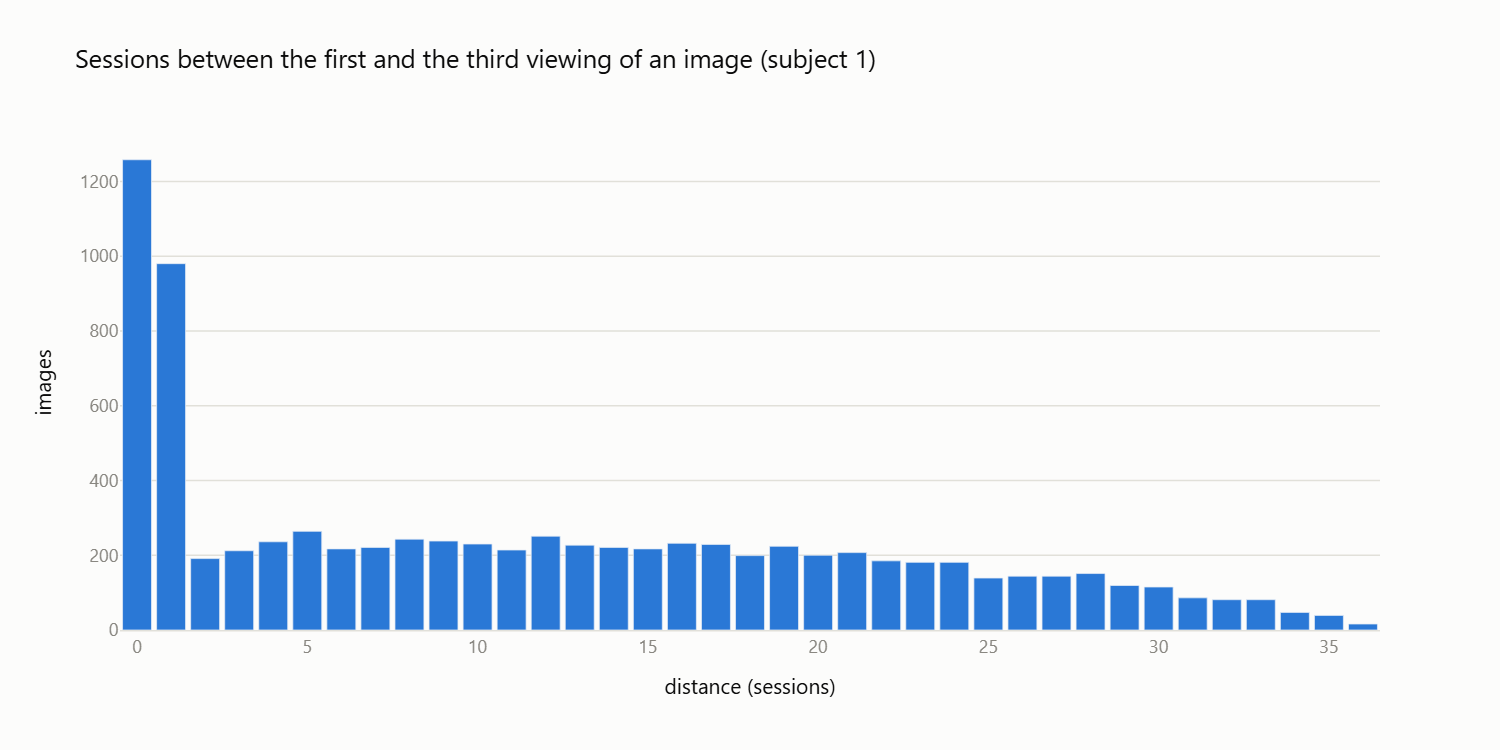

In [8]:
# [1.6.2] Chart: distribution of the distance
# Sessions between the first and the third viewing
sessions_wide = trials_used.pivot(index="nsdId", columns="rep", values="session")
complete = sessions_wide.dropna()                 # only images with 3 repetitions
gap = (complete[3] - complete[1]).astype(int)     # sessions between first and third viewing

print("Images with 3 repetitions:", len(gap))
print(f"All 3 in the same session: {(gap == 0).mean():.1%}")
gap.describe().round(1).to_frame("distance (sessions)").T

gap_count = gap.value_counts().sort_index()

fig = go.Figure()
fig.add_bar(
    x=gap_count.index,
    y=gap_count.values,
    marker=dict(color=BLUE),
    hovertemplate="distance of %{x} sessions: %{y} images<extra></extra>",
)
fig.update_layout(bargap=0.15)
style(fig,
      title="Sessions between the first and the third viewing of an image (subject 1)",
      xaxis_title="distance (sessions)",
      yaxis_title="images")
fig.show()

## 7. The four subjects used in the paper

The paper uses four subjects: 1, 2, 5 and 7. We repeat the count of section 5 for each of them.

In [9]:
# [1.7.1] Train and test counts for subjects 1, 2, 5 and 7
last_trial = N_SESSIONS_USED * TRIALS_PER_SESSION

rows = []
for s in [1, 2, 5, 7]:
    reps = stim.loc[stim[f"subject{s}"] == 1, [f"subject{s}_rep{k}" for k in range(3)]]
    n_reps = ((reps > 0) & (reps <= last_trial)).sum(axis=1)
    shared = stim.loc[reps.index, "shared1000"]
    rows.append({
        "subject": f"subj{s:02d}",
        "train images": int((n_reps[~shared] > 0).sum()),
        "train trials": int(n_reps[~shared].sum()),
        "test images": int((n_reps[shared] > 0).sum()),
        "test trials": int(n_reps[shared].sum()),
    })

pd.DataFrame(rows).set_index("subject")

,train images,train trials,test images,test trials
subject,,,,
subj01,8859,24980,982,2770
subj02,8859,24980,982,2770
subj05,8859,24980,982,2770
subj07,8859,24980,982,2770


# Part 2 — Image content: COCO captions and object categories

NSD images come from COCO, and COCO has human annotations. This part describes **what is in the images** of subject 1:

1. Captions, linked to NSD through `cocoId`.
2. Caption length.
3. Vocabulary.
4. Object categories.
5. The 12 concepts used in the paper.
6. Train versus test.
7. The four subjects.

In [10]:
# [2.0.1] Imports, paths and a common chart style
import json
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go

DATA = Path("..")
COCO_ZIP = DATA / "coco_annotations" / "annotations_trainval2017.zip"
CAPTIONS_CACHE = DATA / "coco_annotations" / "nsd_captions.csv"
INSTANCES_CACHE = DATA / "coco_annotations" / "nsd_instances.csv"
TRIALS_PER_SESSION = 750
N_SESSIONS_USED = 37

import plotly.io as pio

# Each chart is saved twice: interactive (Jupyter, VS Code) and as a static image (shown on GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 1.5
pio.defaults.default_width = 1000
pio.defaults.default_height = 500

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
BLUE_RAMP = ["#86b6ef", "#2a78d6", "#104281"]   # light to dark, for ordered categories


def style(fig, title, xaxis_title=None, yaxis_title=None):
    fig.update_layout(
        title=title,
        paper_bgcolor=SURFACE,
        plot_bgcolor=SURFACE,
        font=dict(family="system-ui, 'Segoe UI', sans-serif", color=INK),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
        margin=dict(t=90),
    )
    fig.update_xaxes(showgrid=False, linecolor=GRID, tickfont_color=MUTED)
    fig.update_yaxes(gridcolor=GRID, zeroline=False, tickfont_color=MUTED)
    # Axis titles are set only when given, so charts with several panels keep their own
    if xaxis_title is not None:
        fig.update_xaxes(title_text=xaxis_title)
    if yaxis_title is not None:
        fig.update_yaxes(title_text=yaxis_title)
    return fig

## 1. Loading captions and linking them to NSD

A caption record in COCO looks like this; `image_id` is the `cocoId` of the NSD table:

```json
{"image_id": 179765, "id": 38, "caption": "A black Honda motorcycle parked in front of a garage."}
```

In [11]:
# [2.1.3] Attach the captions to the images of subject 1
# The images of subject 1, with train / test label
stim = pd.read_csv(DATA / "nsd_stim_info_merged.csv", index_col=0)

rep_cols = ["subject1_rep0", "subject1_rep1", "subject1_rep2"]
last_trial = N_SESSIONS_USED * TRIALS_PER_SESSION

images = stim.loc[stim["subject1"] == 1, ["nsdId", "cocoId", "cocoSplit", "shared1000"]].copy()
reps = stim.loc[images.index, rep_cols]
images["n_reps"] = ((reps > 0) & (reps <= last_trial)).sum(axis=1)
images["set"] = images["shared1000"].map({True: "test", False: "train"})
images = images[images["n_reps"] > 0]

images["set"].value_counts().to_frame("images")

# Read the captions from the COCO archive
if CAPTIONS_CACHE.exists():
    captions_all = pd.read_csv(CAPTIONS_CACHE)
else:
    parts = []
    with zipfile.ZipFile(COCO_ZIP) as z:
        for split in ["train2017", "val2017"]:
            with z.open(f"annotations/captions_{split}.json") as f:
                parts.append(pd.DataFrame(json.load(f)["annotations"]))
    captions_all = pd.concat(parts, ignore_index=True)
    captions_all = captions_all.rename(columns={"image_id": "cocoId", "id": "captionId"})
    captions_all = captions_all[captions_all["cocoId"].isin(stim["cocoId"])]
    captions_all["caption"] = captions_all["caption"].str.strip()
    captions_all.to_csv(CAPTIONS_CACHE, index=False)

print("Captions for all NSD images:", len(captions_all))
print("NSD images with at least one caption:", captions_all["cocoId"].nunique(), "of", len(stim))

captions = images[["nsdId", "cocoId", "set"]].merge(captions_all, on="cocoId", how="left")

print("Captions for subject 1:", len(captions))
print("Images without any caption:", captions["caption"].isna().sum())

pd.set_option("display.max_colwidth", 100)
captions[captions["nsdId"] == captions["nsdId"].iloc[0]]

Captions for all NSD images: 365193
NSD images with at least one caption: 73000 of 73000
Captions for subject 1: 49230
Images without any caption: 0


,nsdId,cocoId,set,captionId,caption
0,13,24610,train,162385,A disorderly living area is free from decorative elements.
1,13,24610,train,168364,"A small living space with a couch, desk, chair, and bookcase."
2,13,24610,train,170512,There is a laptop computer in a room with a couch and a bookcase.
3,13,24610,train,175837,A simple room with minimal decor and furniture.
4,13,24610,train,178792,A small room with a computer and bookcase.


## 2. Caption length

Length is measured in words. Tokenization is simple: lowercase, then sequences of letters (no punctuation, no digits).

In [12]:
# [2.2.2] Descriptive statistics of caption length
# Tokenize, and count captions per image
def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

captions["tokens"] = captions["caption"].apply(tokenize)
captions["n_words"] = captions["tokens"].str.len()

(captions.groupby("nsdId").size()
         .value_counts().sort_index()
         .rename_axis("captions per image").to_frame("images"))

stats = ["size", "mean", "std", "min", "median", "max"]

length_stats = captions.groupby("set")["n_words"].agg(stats)   # train and test
length_stats.loc["total"] = captions["n_words"].agg(stats)     # everything together
length_stats.round(2)

,size,mean,std,min,median,max
set,,,,,,
test,4913,10.37,2.25,7,10.0,40
train,44317,10.45,2.38,5,10.0,45
total,49230,10.44,2.37,5,10.0,45


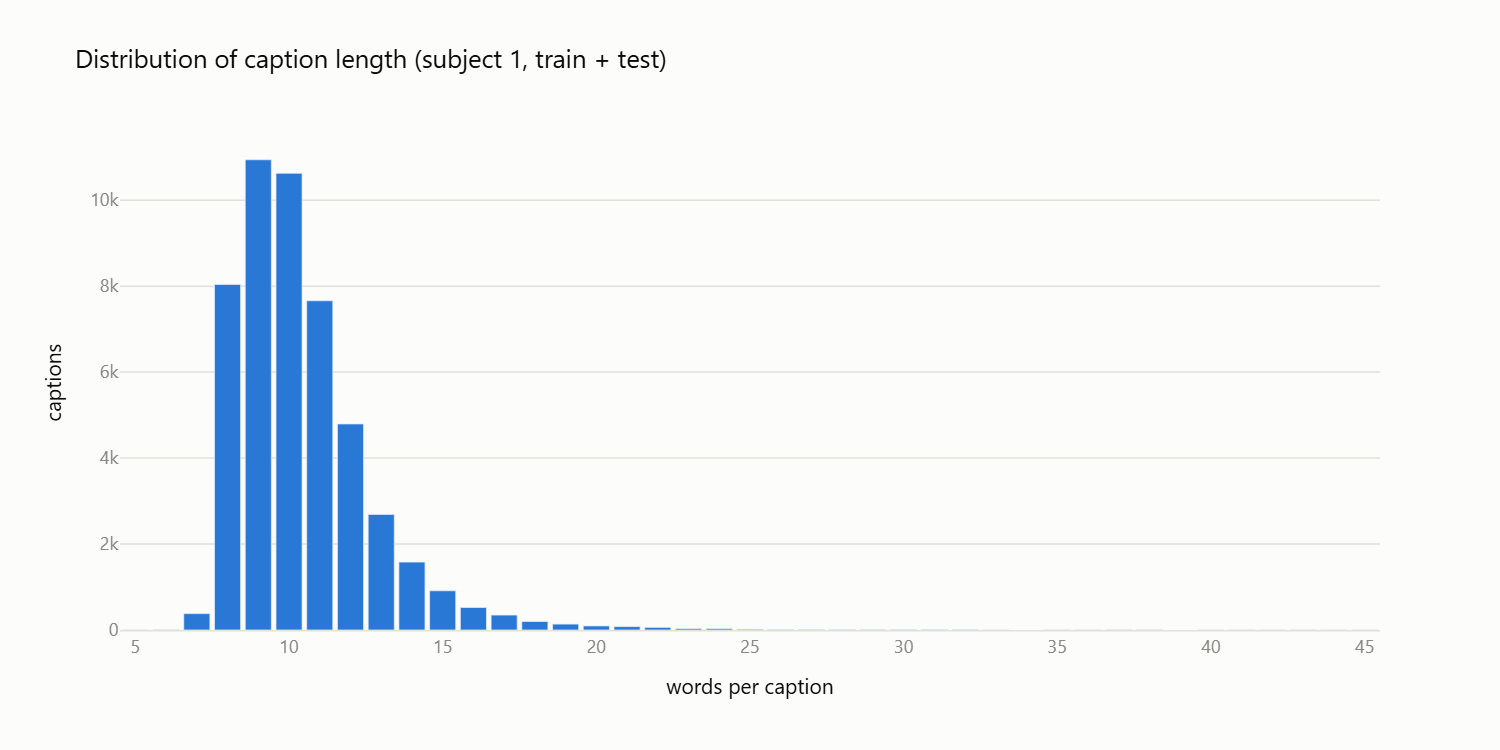

In [13]:
# [2.2.3] Chart: distribution of caption length
length_count = captions["n_words"].value_counts().sort_index()

fig = go.Figure()
fig.add_bar(
    x=length_count.index,
    y=length_count.values,
    marker=dict(color=BLUE),
    hovertemplate="%{x} words: %{y} captions<extra></extra>",
)
fig.update_layout(bargap=0.15)
style(fig,
      title="Distribution of caption length (subject 1, train + test)",
      xaxis_title="words per caption",
      yaxis_title="captions")
fig.show()

## 3. Vocabulary

- **tokens** = all words, with repetitions;
- **types** = distinct words (vocabulary size);
- **type-token ratio (TTR)** = types / tokens.

TTR decreases as a corpus grows, so train (large) and test (small) cannot be compared directly. We also compute it on a sample of training images of the same size as the test set, keeping all captions of each sampled image.

In [14]:
# [2.3.1] Tokens, types and type-token ratio
def vocab_stats(frame):
    tokens = frame["tokens"].explode().dropna()
    return {
        "captions": len(frame),
        "tokens": len(tokens),
        "types": tokens.nunique(),
        "TTR": round(tokens.nunique() / len(tokens), 4),
    }


train_caps = captions[captions["set"] == "train"]
test_caps = captions[captions["set"] == "test"]

# Sample of train with the same number of images as test, keeping all captions of each image
sample_ids = (train_caps["nsdId"].drop_duplicates()
              .sample(test_caps["nsdId"].nunique(), random_state=0))
train_sample = train_caps[train_caps["nsdId"].isin(sample_ids)]

pd.DataFrame({
    "train": vocab_stats(train_caps),
    "test": vocab_stats(test_caps),
    "train (image sample, size of test)": vocab_stats(train_sample),
    "total": vocab_stats(captions),
}).T.astype({"captions": int, "tokens": int, "types": int})

,captions,tokens,types,TTR
train,44317,463042,9049,0.0195
test,4913,50966,3037,0.0596
"train (image sample, size of test)",4913,51597,3240,0.0628
total,49230,514008,9412,0.0183


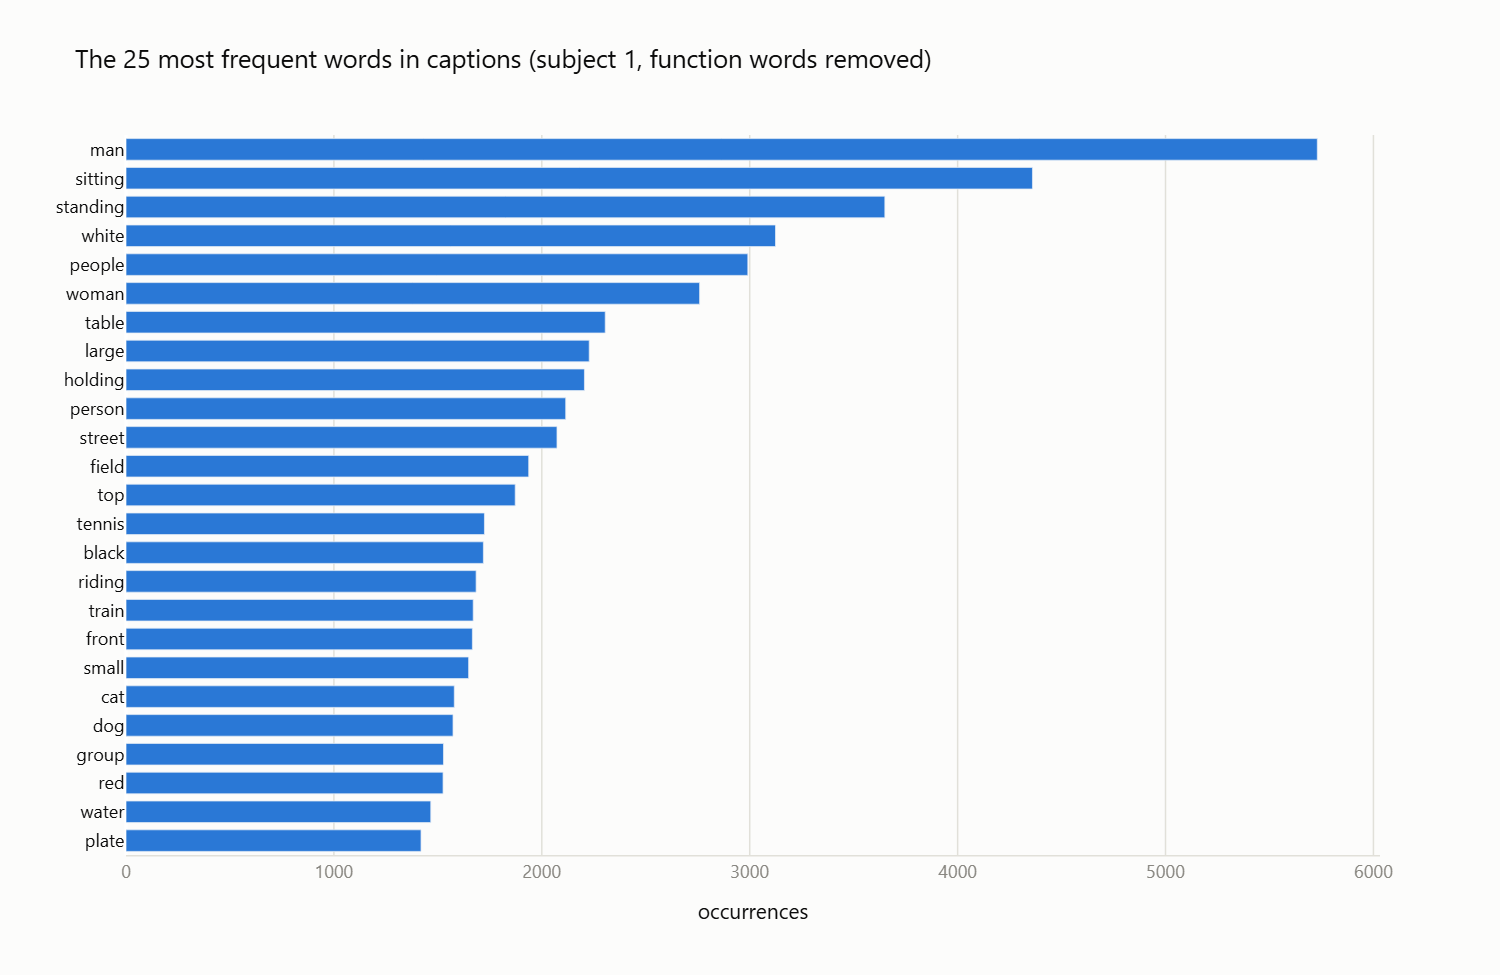

In [15]:
# [2.3.3] Chart: top 25 words
# The most frequent content words
STOPWORDS = set("""
a an the of on in with and is are to at it its there that this by for from as be has have
next near up down his her their some two one while being other very
""".split())

words = captions["tokens"].explode().dropna()
content_words = words[~words.isin(STOPWORDS)]

# Frequency as number of occurrences, and as percent of images with the word in at least one caption
top = content_words.value_counts().head(25).rename("occurrences").to_frame()
word_images = (captions[["nsdId", "tokens"]].explode("tokens")
               .drop_duplicates().groupby("tokens").size())
top["% of images"] = (word_images.reindex(top.index) / captions["nsdId"].nunique() * 100).round(1)
top.head(10)

plot_data = top.iloc[::-1]   # most frequent at the top

fig = go.Figure()
fig.add_bar(
    x=plot_data["occurrences"],
    y=plot_data.index,
    orientation="h",
    marker=dict(color=BLUE),
    customdata=plot_data["% of images"],
    hovertemplate="%{y}: %{x} occurrences, in %{customdata}% of images<extra></extra>",
)
fig.update_layout(height=650, bargap=0.25)
style(fig,
      title="The 25 most frequent words in captions (subject 1, function words removed)",
      xaxis_title="occurrences",
      yaxis_title="")
fig.update_xaxes(showgrid=True, gridcolor=GRID)
fig.update_yaxes(showgrid=False, tickfont_color=INK)
fig.show()

## 4. Object categories

Besides captions, COCO marks the **objects** in each image, one record per object:

```json
{"image_id": 289343, "category_id": 18, "area": 702.1, "iscrowd": 0, ...}
```

There are 80 categories (person, car, dog…) grouped in 12 supercategories.

**Limitation:** NSD cropped the COCO images to a square. An object at the edge of the original image may not be visible in what the subject saw. Here we use the annotations of the full image.

In [16]:
# [2.4.3] Objects and distinct categories per image
# Read the object annotations from the COCO archive
if INSTANCES_CACHE.exists():
    objects_all = pd.read_csv(INSTANCES_CACHE)
else:
    nsd_coco_ids = set(stim["cocoId"])
    rows = []
    with zipfile.ZipFile(COCO_ZIP) as z:
        for split in ["train2017", "val2017"]:
            with z.open(f"annotations/instances_{split}.json") as f:
                data = json.load(f)
            categories = {c["id"]: (c["name"], c["supercategory"]) for c in data["categories"]}
            image_area = {im["id"]: im["width"] * im["height"] for im in data["images"]}
            for ann in data["annotations"]:
                coco_id = ann["image_id"]
                if coco_id in nsd_coco_ids:
                    name, supercategory = categories[ann["category_id"]]
                    rows.append({
                        "cocoId": coco_id,
                        "category": name,
                        "supercategory": supercategory,
                        "area_frac": ann["area"] / image_area[coco_id],
                        "iscrowd": ann["iscrowd"],
                    })
            del data
    objects_all = pd.DataFrame(rows)
    objects_all.to_csv(INSTANCES_CACHE, index=False)

print("Annotated objects in NSD images:", len(objects_all))
print("Categories:", objects_all["category"].nunique(),
      "| supercategories:", objects_all["supercategory"].nunique())

# Objects in the images of subject 1
objects = images[["nsdId", "cocoId", "set"]].merge(objects_all, on="cocoId", how="inner")

print("Objects in the images of subject 1:", len(objects))
objects.head()

per_image = images.set_index("nsdId")[["set"]].copy()
per_image["n_objects"] = objects.groupby("nsdId").size().reindex(per_image.index, fill_value=0)
per_image["n_categories"] = (objects.groupby("nsdId")["category"].nunique()
                             .reindex(per_image.index, fill_value=0))

print("Images without any annotated object:", (per_image["n_objects"] == 0).sum(),
      "of", len(per_image))

stats = ["mean", "std", "median", "max"]
pd.concat({
    "objects per image": per_image.groupby("set")["n_objects"].agg(stats),
    "distinct categories per image": per_image.groupby("set")["n_categories"].agg(stats),
}, axis=1).round(2)

Annotated objects in NSD images: 516477
Categories: 80 | supercategories: 12
Objects in the images of subject 1: 69269
Images without any annotated object: 0 of 9841


objects per image                  distinct categories per image        \
                   mean   std median max                          mean   std   
set                                                                            
test               6.17  7.34    3.0  52                           2.5  1.77   
train              7.13  7.71    4.0  78                           2.8  1.79   

                  
      median max  
set               
test     2.0  13  
train    2.0  15

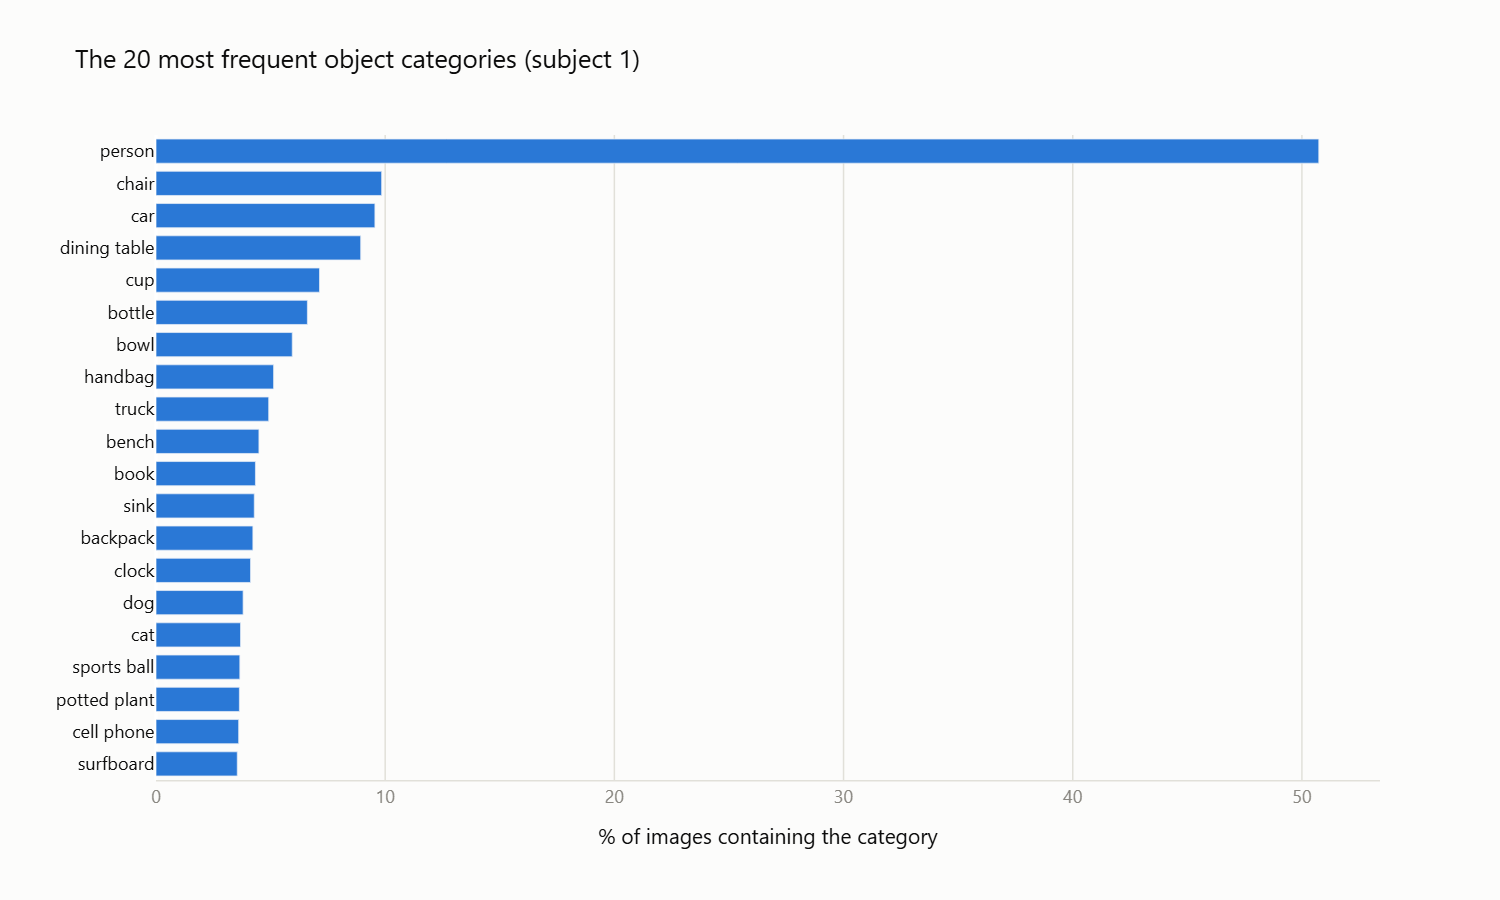

In [17]:
# [2.4.6] Chart: top 20 categories
# The most frequent categories (percent of images)
n_images = len(per_image)

# One row per (image, category), so that each image counts once
image_category = objects[["nsdId", "set", "category", "supercategory"]].drop_duplicates()

category_pct = (image_category.groupby("category").size() / n_images * 100).sort_values(ascending=False)
category_pct.head(10).round(1).to_frame("% of images")

plot_data = category_pct.head(20).iloc[::-1]   # most frequent at the top

fig = go.Figure()
fig.add_bar(
    x=plot_data.values,
    y=plot_data.index,
    orientation="h",
    marker=dict(color=BLUE),
    hovertemplate="%{y}: in %{x:.1f}% of images<extra></extra>",
)
fig.update_layout(height=600, bargap=0.25)
style(fig,
      title="The 20 most frequent object categories (subject 1)",
      xaxis_title="% of images containing the category",
      yaxis_title="")
fig.update_xaxes(showgrid=True, gridcolor=GRID)
fig.update_yaxes(showgrid=False, tickfont_color=INK)
fig.show()

## 5. The concepts used in the paper

The paper uses 12 concepts in 6 opposite pairs. For each concept the authors select 100 training images and average their fMRI patterns.

They select the images with CLIP, directly on the image. We do not have the images here, so we use a **caption-based approximation**: an image "contains" a concept if one of the words below appears in its captions. The lists are deliberately minimal.

We count in two ways:

- **permissive:** the concept appears in at least 1 caption;
- **strict:** it appears in at least 3 captions (most annotators mentioned it).

In [18]:
# [2.5.1] The word list for each concept
# Opposite pairs are next to each other
CONCEPTS = {
    "man":     ["man", "men"],
    "woman":   ["woman", "women"],
    "indoor":  ["indoor", "indoors", "inside"],
    "outdoor": ["outdoor", "outdoors", "outside"],
    "summer":  ["summer"],
    "winter":  ["winter", "snow", "snowy"],
    "day":     ["day", "daytime", "sunny"],
    "night":   ["night", "nighttime", "dark"],
    "crowded": ["crowded", "crowd"],
    "empty":   ["empty"],
    "happy":   ["happy", "smiling"],
    "sad":     ["sad"],
}

In [19]:
# [2.5.3] Images per concept, train and test, at both thresholds
# Count, for each image, how many captions mention each concept
# Step 1: one row per caption, one column per concept (True / False)
caption_has = pd.DataFrame({
    concept: captions["tokens"].apply(lambda tokens: any(word in tokens for word in words))
    for concept, words in CONCEPTS.items()
})

# Step 2: one row per image, value = number of captions that mention the concept
mentions = caption_has.groupby(captions["nsdId"]).sum()
mentions["set"] = images.set_index("nsdId")["set"]

mentions.head()

concept_names = list(CONCEPTS)
is_train = mentions["set"] == "train"
is_test = mentions["set"] == "test"

concept_table = pd.DataFrame({
    "train, >=1 caption": (mentions.loc[is_train, concept_names] >= 1).sum(),
    "train, >=3 captions": (mentions.loc[is_train, concept_names] >= 3).sum(),
    "test, >=1 caption": (mentions.loc[is_test, concept_names] >= 1).sum(),
    "test, >=3 captions": (mentions.loc[is_test, concept_names] >= 3).sum(),
})
concept_table

,"train, >=1 caption","train, >=3 captions","test, >=1 caption","test, >=3 captions"
man,2219,1102,197,103
woman,1014,561,102,54
indoor,381,12,39,2
outdoor,567,25,73,4
summer,2,0,1,0
winter,440,257,60,36
day,321,1,48,0
night,224,29,23,4
crowded,209,5,12,2
empty,193,9,25,1


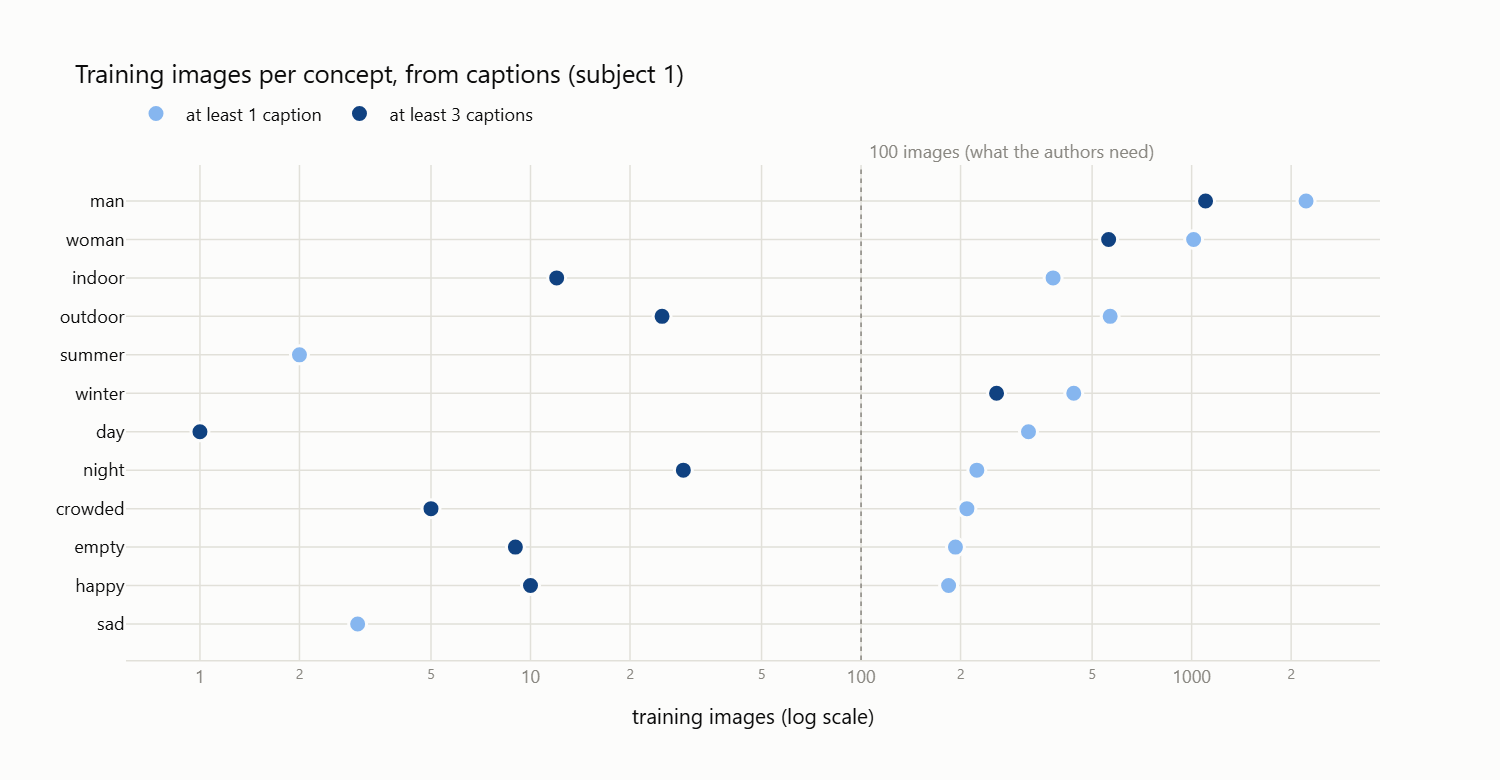

In [20]:
# [2.5.4] Chart: are there enough training images per concept?
plot_table = concept_table.iloc[::-1]   # first concept at the top
series = [
    ("train, >=1 caption", "at least 1 caption", "#86b6ef"),
    ("train, >=3 captions", "at least 3 captions", "#104281"),
]

fig = go.Figure()
for column, label, color in series:
    values = plot_table[column].where(plot_table[column] > 0)   # 0 cannot be drawn on a log axis
    fig.add_scatter(
        x=values,
        y=plot_table.index,
        mode="markers",
        name=label,
        marker=dict(color=color, size=12, line=dict(color=SURFACE, width=2)),
        hovertemplate="%{y}: %{x} training images (" + label + ")<extra></extra>",
    )

fig.add_vline(x=100, line=dict(color=MUTED, dash="dot", width=1))
fig.add_annotation(x=2, y=1.0, yref="paper", yanchor="bottom", xanchor="left", showarrow=False,
                   text=" 100 images (what the authors need)", font=dict(color=MUTED, size=12))

style(fig,
      title="Training images per concept, from captions (subject 1)",
      xaxis_title="training images (log scale)",
      yaxis_title="")
fig.update_layout(height=520, margin=dict(t=110),
                  legend=dict(orientation="h", yanchor="bottom", y=1.06, x=0))
fig.update_xaxes(type="log", showgrid=True, gridcolor=GRID)
fig.update_yaxes(showgrid=True, gridcolor=GRID, tickfont_color=INK)
fig.show()

All images of subject 1: 50.7% contain a person


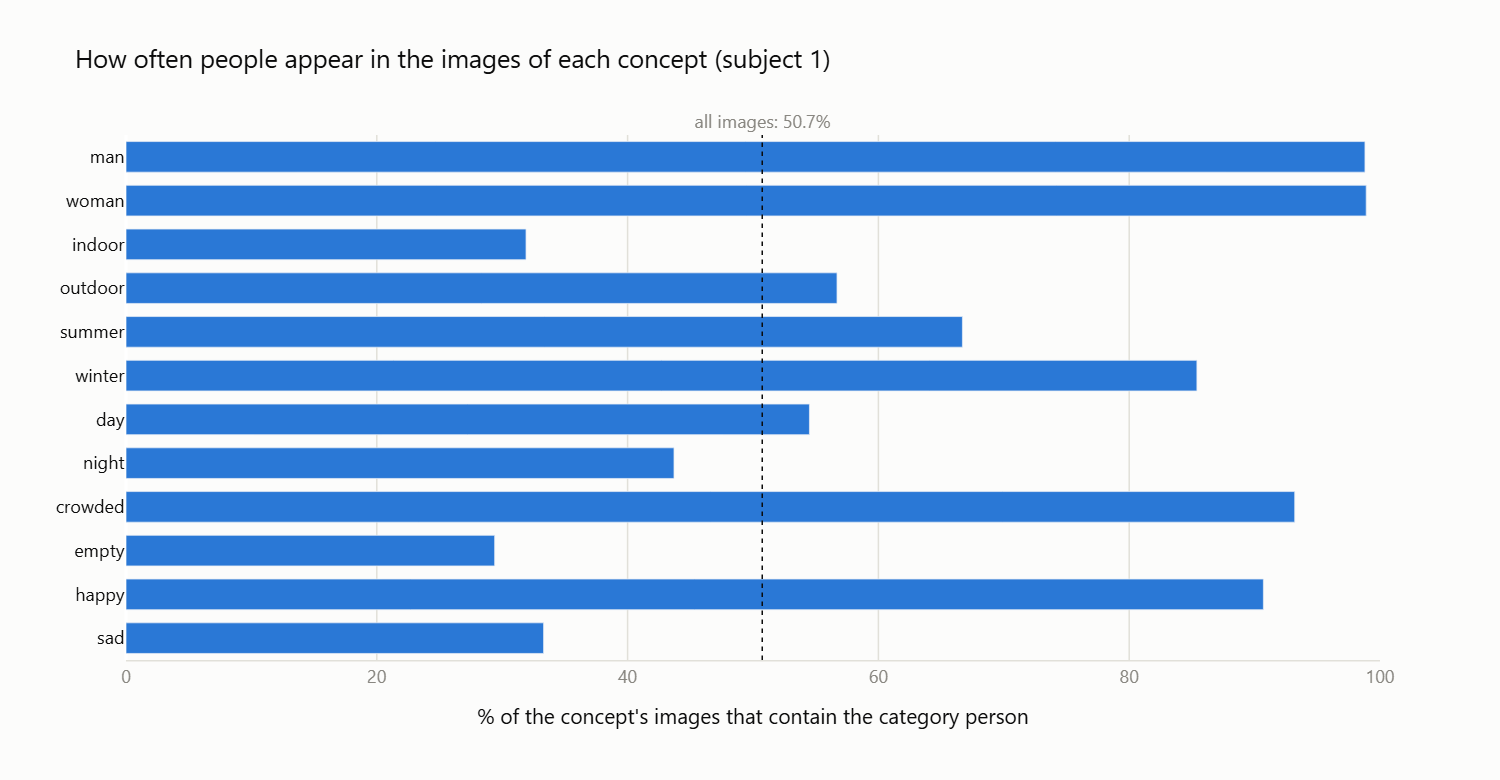

In [21]:
# [2.5.6] Chart: overlap between concepts and people
# How often people appear in the images of each concept
has_person = per_image.index.isin(objects.loc[objects["category"] == "person", "nsdId"])
has_person = pd.Series(has_person, index=per_image.index)
baseline = has_person.mean() * 100

overlap = pd.DataFrame({
    "images with the concept": [(mentions[c] >= 1).sum() for c in concept_names],
    "% with person": [has_person[mentions.index[mentions[c] >= 1]].mean() * 100 for c in concept_names],
}, index=concept_names).round(1)

print(f"All images of subject 1: {baseline:.1f}% contain a person")
overlap

plot_data = overlap.iloc[::-1]

fig = go.Figure()
fig.add_bar(
    x=plot_data["% with person"],
    y=plot_data.index,
    orientation="h",
    marker=dict(color=BLUE),
    customdata=plot_data["images with the concept"],
    hovertemplate="%{y}: %{x:.1f}% contain a person (of %{customdata} images)<extra></extra>",
)
fig.add_vline(x=baseline, line=dict(color=INK, dash="dot", width=1))
fig.add_annotation(x=baseline, y=1.0, yref="paper", yanchor="bottom", showarrow=False,
                   text=f"all images: {baseline:.1f}%", font=dict(color=MUTED, size=12))

style(fig,
      title="How often people appear in the images of each concept (subject 1)",
      xaxis_title="% of the concept's images that contain the category person",
      yaxis_title="")
fig.update_layout(height=520, bargap=0.3, margin=dict(t=90))
fig.update_xaxes(range=[0, 100], showgrid=True, gridcolor=GRID)
fig.update_yaxes(showgrid=False, tickfont_color=INK)
fig.show()

## 6. Train versus test: do they have the same content?

The decoder is trained on the training images and evaluated on the test images. We compare the two sets in three steps: supercategories, all 80 categories, and the number of objects per image.

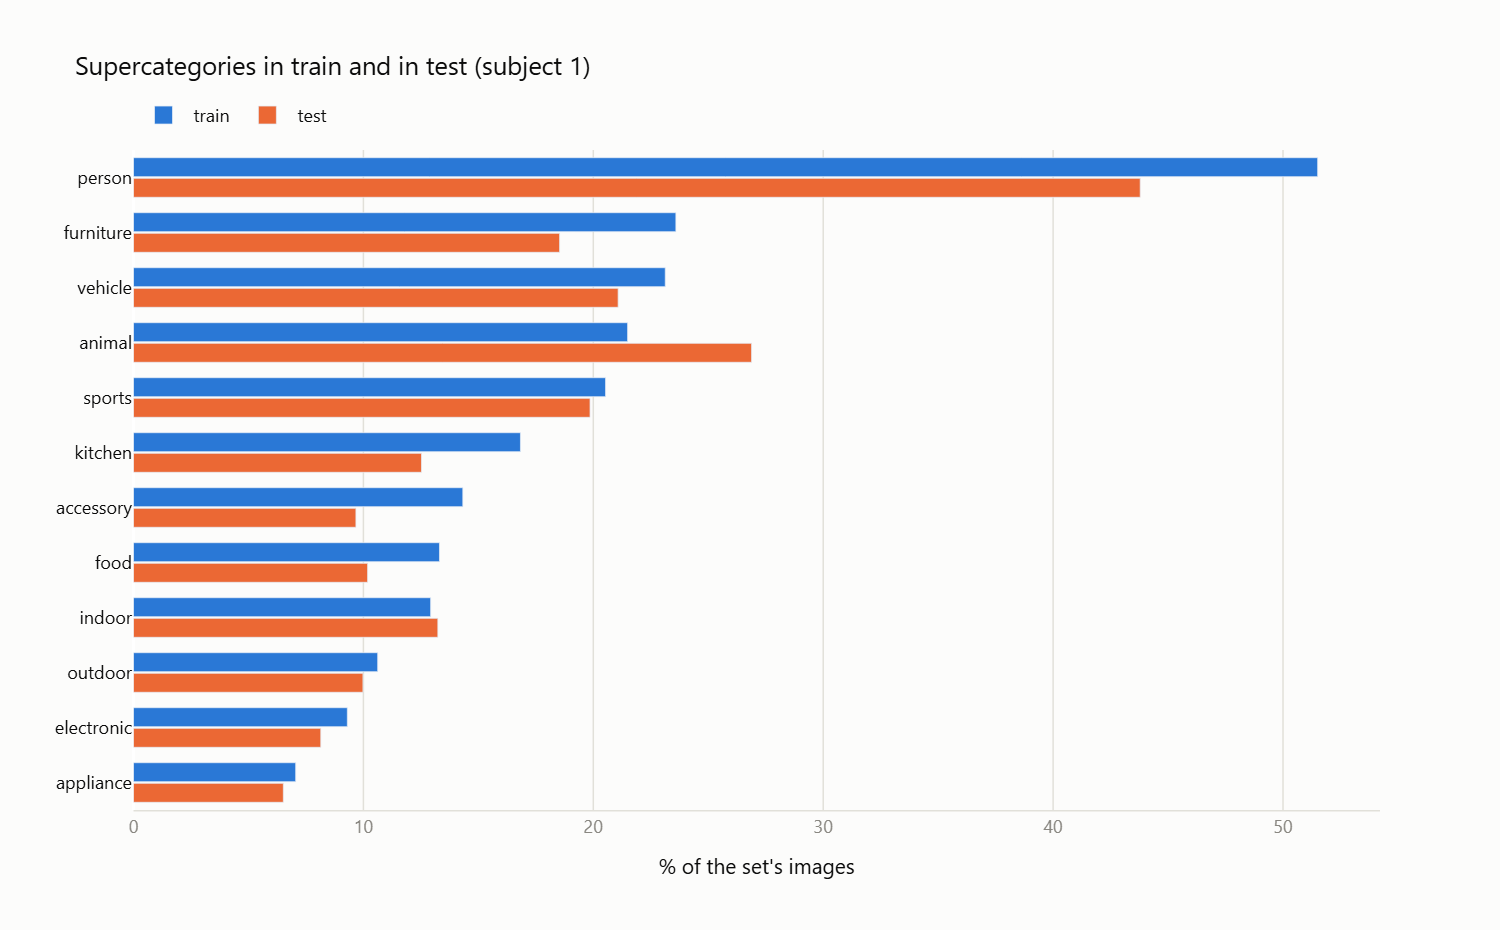

In [22]:
# [2.6.2] Chart: supercategories in train and test
# Supercategories in train and in test
n_train = (per_image["set"] == "train").sum()
n_test = (per_image["set"] == "test").sum()

def pct_images(column):
    # Percent of images of each set that contain each value of the column
    pairs = image_category[["nsdId", "set", column]].drop_duplicates()
    counts = pairs.groupby([column, "set"]).size().unstack("set", fill_value=0)
    return pd.DataFrame({
        "train %": counts["train"] / n_train * 100,
        "test %": counts["test"] / n_test * 100,
    })

super_compare = pct_images("supercategory").sort_values("train %", ascending=False)
super_compare["difference (test - train)"] = super_compare["test %"] - super_compare["train %"]
super_compare.round(1)

plot_data = super_compare.iloc[::-1]

fig = go.Figure()
for column, label, color in [("test %", "test", ORANGE), ("train %", "train", BLUE)]:
    fig.add_bar(
        x=plot_data[column],
        y=plot_data.index,
        orientation="h",
        name=label,
        marker=dict(color=color),
        hovertemplate="%{y}, " + label + ": %{x:.1f}% of images<extra></extra>",
    )

style(fig,
      title="Supercategories in train and in test (subject 1)",
      xaxis_title="% of the set's images",
      yaxis_title="")
fig.update_layout(barmode="group", height=620, bargap=0.25, bargroupgap=0.08, margin=dict(t=100),
                  legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0, traceorder="reversed"))
fig.update_xaxes(showgrid=True, gridcolor=GRID)
fig.update_yaxes(showgrid=False, tickfont_color=INK)
fig.show()

Correlation between train and test percentages (80 categories): 0.987


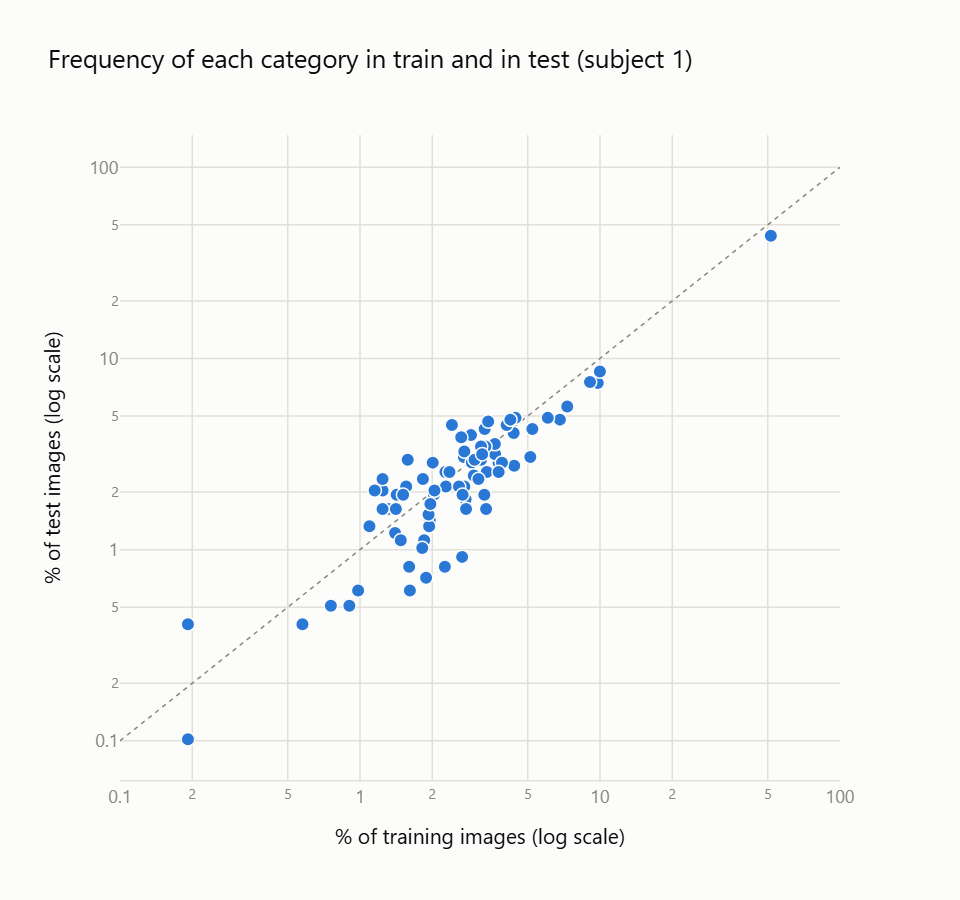

In [23]:
# [2.6.4] Chart: every category, train against test
# All 80 categories: correlation and largest differences
cat_compare = pct_images("category")
correlation = cat_compare["train %"].corr(cat_compare["test %"])
print(f"Correlation between train and test percentages (80 categories): {correlation:.3f}")

cat_compare["difference (test - train)"] = cat_compare["test %"] - cat_compare["train %"]
order = cat_compare["difference (test - train)"].abs().sort_values(ascending=False).index
cat_compare.loc[order].head(8).round(1)

low = 0.1
high = 100

fig = go.Figure()
fig.add_scatter(
    x=[low, high], y=[low, high], mode="lines",
    line=dict(color=MUTED, dash="dot", width=1), hoverinfo="skip", showlegend=False,
)
fig.add_scatter(
    x=cat_compare["train %"],
    y=cat_compare["test %"].where(cat_compare["test %"] > 0),   # 0 cannot be drawn on a log axis
    mode="markers",
    text=cat_compare.index,
    marker=dict(color=BLUE, size=9, line=dict(color=SURFACE, width=1)),
    hovertemplate="%{text}<br>train: %{x:.1f}%<br>test: %{y:.1f}%<extra></extra>",
    showlegend=False,
)

style(fig,
      title="Frequency of each category in train and in test (subject 1)",
      xaxis_title="% of training images (log scale)",
      yaxis_title="% of test images (log scale)")
fig.update_layout(height=600, width=640)
fig.update_xaxes(type="log", showgrid=True, gridcolor=GRID)
fig.update_yaxes(type="log")
fig.show()

Test mean: 6.17 objects per image
Means of the train samples: between 6.41 and 8.08, on average 7.13
Train samples with a mean as low as the test mean: 0.00%


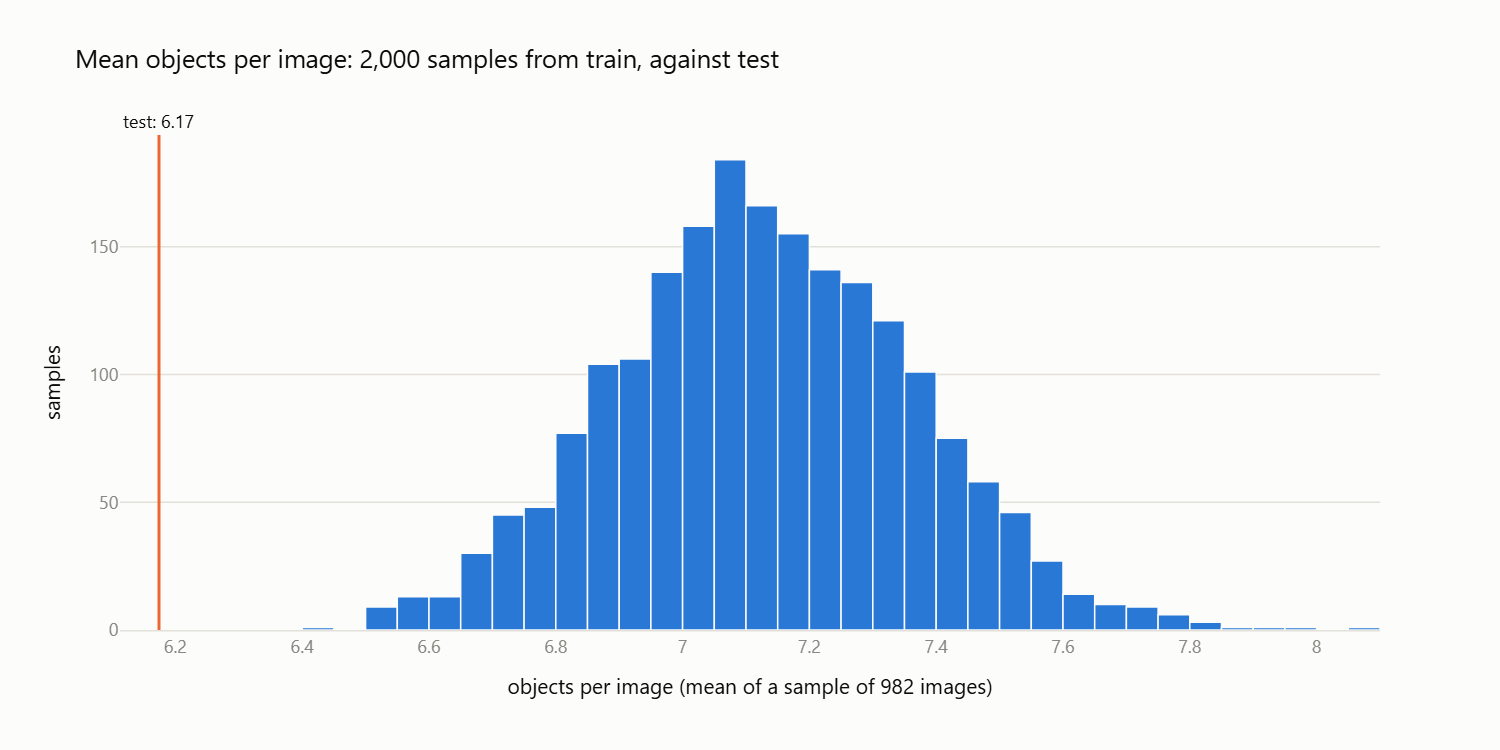

In [24]:
# [2.6.6] Chart: test mean against 2,000 random training samples
# Is the test set really simpler? A resampling check
rng = np.random.default_rng(0)
train_objects = per_image.loc[per_image["set"] == "train", "n_objects"].to_numpy()
test_mean = per_image.loc[per_image["set"] == "test", "n_objects"].mean()

sample_means = np.array([
    rng.choice(train_objects, size=n_test, replace=False).mean()
    for _ in range(2000)
])

print(f"Test mean: {test_mean:.2f} objects per image")
print(f"Means of the train samples: between {sample_means.min():.2f} and {sample_means.max():.2f}, "
      f"on average {sample_means.mean():.2f}")
print(f"Train samples with a mean as low as the test mean: {(sample_means <= test_mean).mean():.2%}")

fig = go.Figure()
fig.add_histogram(
    x=sample_means,
    xbins=dict(size=0.05),
    marker=dict(color=BLUE, line=dict(color=SURFACE, width=1)),
    hovertemplate="mean %{x}: %{y} samples<extra></extra>",
)
fig.add_vline(x=test_mean, line=dict(color=ORANGE, width=2))
fig.add_annotation(x=test_mean, y=1.0, yref="paper", yanchor="bottom", showarrow=False,
                   text=f"test: {test_mean:.2f}", font=dict(color=INK, size=12))

style(fig,
      title="Mean objects per image: 2,000 samples from train, against test",
      xaxis_title="objects per image (mean of a sample of 982 images)",
      yaxis_title="samples")
fig.update_layout(margin=dict(t=90))
fig.show()

## 7. The four subjects

Each subject has a different set of 9,000 unique training images. We compare the content of the training sets of subjects 1, 2, 5 and 7. The test set is the same for all subjects.

In [25]:
# [2.7.1] Content of the training set of each subject
caption_words = captions_all.assign(n_words=captions_all["caption"].apply(lambda text: len(tokenize(text))))

columns = {}
for s in [1, 2, 5, 7]:
    reps = stim[[f"subject{s}_rep{k}" for k in range(3)]]
    seen = ((reps > 0) & (reps <= last_trial)).any(axis=1)
    train_ids = stim.loc[seen & ~stim["shared1000"], "cocoId"]
    train_objects_s = objects_all[objects_all["cocoId"].isin(train_ids)]

    summary = {
        "training images": len(train_ids),
        "words per caption (mean)": caption_words.loc[caption_words["cocoId"].isin(train_ids), "n_words"].mean(),
        "objects per image (mean)": len(train_objects_s) / len(train_ids),
    }
    supercategory_pct = (train_objects_s[["cocoId", "supercategory"]].drop_duplicates()
                         .groupby("supercategory").size() / len(train_ids) * 100)
    for name in ["person", "animal", "vehicle", "furniture", "food"]:
        summary[f"% of images with {name}"] = supercategory_pct[name]
    columns[f"subj{s:02d}"] = summary

pd.DataFrame(columns).round(2)

,subj01,subj02,subj05,subj07
training images,8859.00,8859.00,8859.00,8859.00
words per caption (mean),10.45,10.43,10.44,10.45
objects per image (mean),7.13,7.11,6.99,7.12
% of images with person,51.51,50.68,50.48,49.86
% of images with animal,21.49,21.45,21.31,21.53
% of images with vehicle,23.13,23.82,23.37,23.23
% of images with furniture,23.59,23.10,23.50,23.00
% of images with food,13.31,13.29,13.48,13.49


# Part 3 — The fMRI data: mask and betas (subject 1)

This part looks at the brain responses themselves. We use a subsample: **subject 1, sessions 1–5** (3,750 trials out of the 27,750 used in the paper).

1. The 3D volume and the NSDGeneral mask.
2. From a 4D volume to a trial × voxel matrix.
3. Distribution of beta values.
4. Differences between sessions.
5. Voxel quality.
6. Repetitions of the same image.

In [26]:
# [3.0.1] Imports, paths and a common chart style
from itertools import combinations
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

DATA = Path("..")
BETAS_DIR = DATA / "betas" / "subj01"
SESSIONS = [1, 2, 3, 4, 5]
TRIALS_PER_SESSION = 750

import plotly.io as pio

# Each chart is saved twice: interactive (Jupyter, VS Code) and as a static image (shown on GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 1.5
pio.defaults.default_width = 1000
pio.defaults.default_height = 500

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
BLUE_RAMP = ["#86b6ef", "#2a78d6", "#104281"]   # light to dark, for ordered categories


def style(fig, title, xaxis_title=None, yaxis_title=None):
    fig.update_layout(
        title=title,
        paper_bgcolor=SURFACE,
        plot_bgcolor=SURFACE,
        font=dict(family="system-ui, 'Segoe UI', sans-serif", color=INK),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
        margin=dict(t=90),
    )
    fig.update_xaxes(showgrid=False, linecolor=GRID, tickfont_color=MUTED)
    fig.update_yaxes(gridcolor=GRID, zeroline=False, tickfont_color=MUTED)
    # Axis titles are set only when given, so charts with several panels keep their own
    if xaxis_title is not None:
        fig.update_xaxes(title_text=xaxis_title)
    if yaxis_title is not None:
        fig.update_yaxes(title_text=yaxis_title)
    return fig

## 1. The volume and the mask

The scanner divides the head into a 3D grid of **voxels** (cubes of 1.8 mm). The mask `nsdgeneral.nii.gz` has the same grid and gives each voxel a label:

| Value | Meaning |
|---|---|
| −1 | outside the brain |
| 0 | brain, but not visual cortex |
| 1 | the NSDGeneral visual region (what the paper uses) |

In [27]:
# [3.1.1] Load the mask and count voxels by label
mask_img = nib.load(DATA / "nsdgeneral.nii.gz")
mask_volume = mask_img.get_fdata()

print("Grid shape:", mask_volume.shape)
print("Voxel size (mm):", [round(float(z), 1) for z in mask_img.header.get_zooms()])

labels = {-1: "outside the brain", 0: "brain, not visual cortex", 1: "NSDGeneral"}
counts = pd.Series(mask_volume.ravel()).value_counts().sort_index()

pd.DataFrame({
    "meaning": [labels[int(v)] for v in counts.index],
    "voxels": counts.values,
    "% of grid": (counts.values / mask_volume.size * 100).round(1),
}, index=counts.index.astype(int).rename("value"))

Grid shape: (81, 104, 83)
Voxel size (mm): [1.8, 1.8, 1.8]


,meaning,voxels,% of grid
value,,,
-1,outside the brain,592088,84.7
0,"brain, not visual cortex",91380,13.1
1,NSDGeneral,15724,2.2


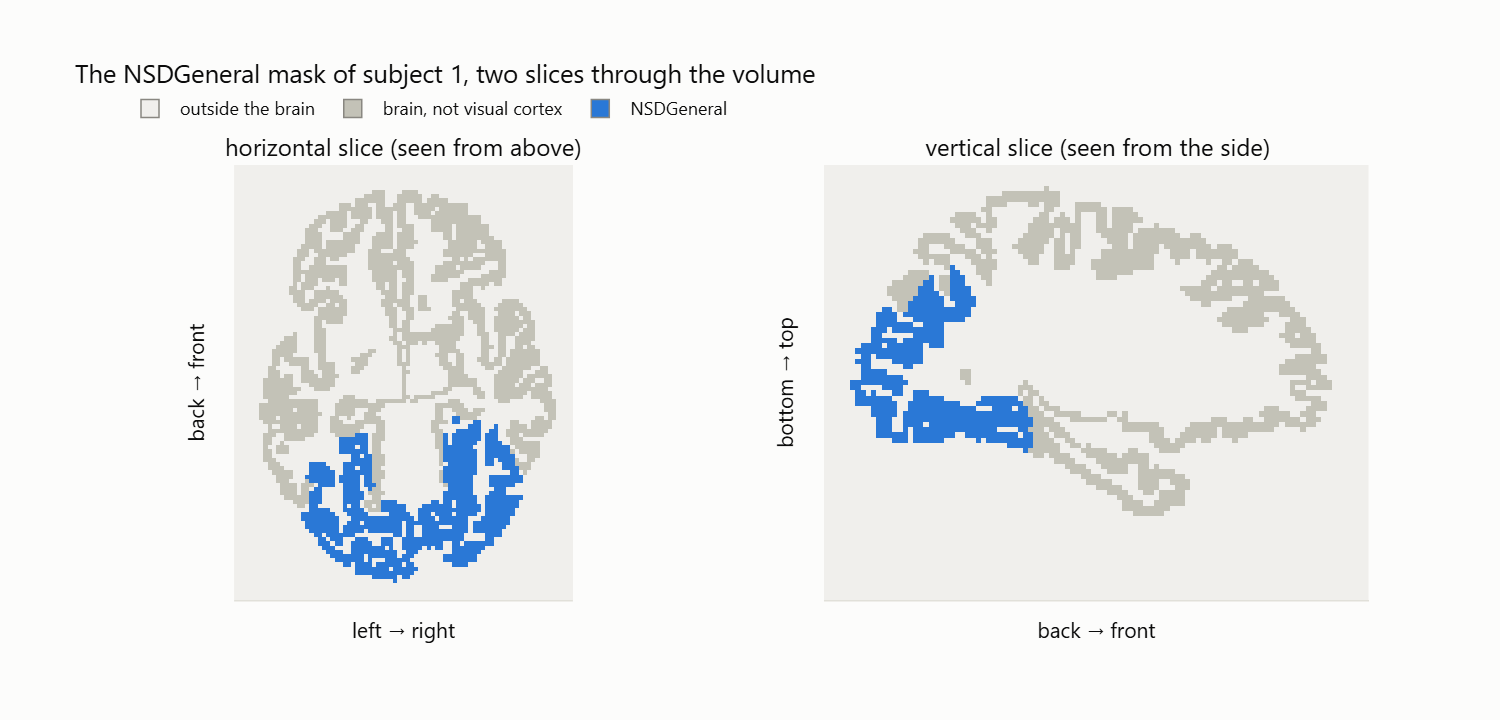

In [28]:
# [3.1.2] Chart: two slices through the mask
Z_SLICE = 35    # horizontal slice (seen from above)
X_SLICE = 28    # vertical slice (seen from the side)

# 3 discrete colors for the values -1, 0, 1
colorscale = [
    [0.0, "#f0efec"], [1 / 3, "#f0efec"],
    [1 / 3, "#c3c2b7"], [2 / 3, "#c3c2b7"],
    [2 / 3, BLUE], [1.0, BLUE],
]

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=["horizontal slice (seen from above)", "vertical slice (seen from the side)"],
)
slices = [
    (mask_volume[:, :, Z_SLICE].T, "left → right", "back → front"),
    (mask_volume[X_SLICE, :, :].T, "back → front", "bottom → top"),
]
for col, (image, x_label, y_label) in enumerate(slices, start=1):
    fig.add_heatmap(
        z=image, zmin=-1, zmax=1, colorscale=colorscale, showscale=False,
        hovertemplate="voxel (%{x}, %{y})<extra></extra>",
        row=1, col=col,
    )
    fig.update_xaxes(title_text=x_label, row=1, col=col, constrain="domain")
    fig.update_yaxes(title_text=y_label, row=1, col=col, scaleanchor=f"x{col}", constrain="domain")

# Legend: one marker per label
for label, color in [("outside the brain", "#f0efec"), ("brain, not visual cortex", "#c3c2b7"), ("NSDGeneral", BLUE)]:
    fig.add_scatter(x=[None], y=[None], mode="markers", name=label,
                    marker=dict(color=color, size=12, symbol="square", line=dict(color=MUTED, width=1)))

style(fig, title="The NSDGeneral mask of subject 1, two slices through the volume")
fig.update_layout(height=480, margin=dict(t=110),
                  legend=dict(orientation="h", yanchor="bottom", y=1.08, x=0))
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(showticklabels=False, showgrid=False)
fig.show()

## 2. From a 4D volume to a trial × voxel matrix

A file `betas_sessionNN.nii.gz` has shape 81 × 104 × 83 × 750: for each voxel of the grid, 750 values, one per trial of the session.

A **beta** = how strongly a voxel responded to the image of one trial. It is a regression coefficient estimated by the NSD authors from the raw signal over time. The files store betas as integers multiplied by 300; dividing by 300 gives the real unit, **percent signal change** relative to baseline.

For each session we read the 4D volume, keep the voxels of the mask, put trials on rows, and divide by 300.

In [29]:
# [3.2.1] Load five sessions into one matrix X
mask = mask_volume == 1
X_CACHE = BETAS_DIR / "X_nsdgeneral_sessions01-05.npy"


def load_session(session):
    img = nib.load(BETAS_DIR / f"betas_session{session:02d}.nii.gz")
    volume = np.asarray(img.dataobj)          # (81, 104, 83, 750), integers
    betas = volume[mask]                      # (15724, 750): only the voxels of the mask
    return betas.T.astype(np.float32) / 300   # (750, 15724): trials on rows, in %


if X_CACHE.exists():
    X = np.load(X_CACHE)
else:
    X = np.concatenate([load_session(s) for s in SESSIONS])
    np.save(X_CACHE, X)

print("Shape of X (trials, voxels):", X.shape)
print(f"Memory: {X.nbytes / 1e6:.0f} MB")

Shape of X (trials, voxels): (3750, 15724)
Memory: 236 MB


In [30]:
# [3.2.2] Link every row of X to an image
stim = pd.read_csv(DATA / "nsd_stim_info_merged.csv", index_col=0)
rep_cols = ["subject1_rep0", "subject1_rep1", "subject1_rep2"]

trials = (
    stim.loc[stim["subject1"] == 1, ["nsdId", "shared1000"] + rep_cols]
        .melt(id_vars=["nsdId", "shared1000"], value_vars=rep_cols, var_name="rep", value_name="trial")
)
trials["rep"] = trials["rep"].str[-1].astype(int) + 1
trials = trials[(trials["trial"] > 0) & (trials["trial"] <= len(X))]
trials["session"] = (trials["trial"] - 1) // TRIALS_PER_SESSION + 1
trials = trials.sort_values("trial").reset_index(drop=True)

assert len(trials) == len(X), "the trial table and X must have the same number of rows"

print("Distinct images in these 5 sessions:", trials["nsdId"].nunique())
print("Example: row 799 of X is trial", trials.loc[799, "trial"],
      "-> image nsdId", trials.loc[799, "nsdId"])
trials.head()

Distinct images in these 5 sessions: 2492
Example: row 799 of X is trial 800 -> image nsdId 3626


,nsdId,shared1000,rep,trial,session
0,46002,True,1,1,1
1,61882,False,1,2,1
2,828,False,1,3,1
3,67573,False,1,4,1
4,16020,False,1,5,1


## 3. Distribution of beta values

All values of `X` together: 3,750 trials × 15,724 voxels ≈ 59 million numbers.

In [31]:
# [3.3.1] Descriptive statistics of all beta values
percentiles = np.percentile(X, [1, 25, 50, 75, 99])

pd.DataFrame({
    "value (% signal change)": [
        X.mean(), X.std(), X.min(), *percentiles, X.max(),
    ],
}, index=["mean", "standard deviation", "minimum", "1st percentile", "25th percentile",
          "median", "75th percentile", "99th percentile", "maximum"]).round(2)

,value (% signal change)
mean,1.36
standard deviation,2.64
minimum,-109.23
1st percentile,-3.39
25th percentile,-0.06
median,0.95
75th percentile,2.28
99th percentile,10.51
maximum,109.22


In [32]:
# [3.3.3] Mean and standard deviation of each voxel
voxel_mean = X.mean(axis=0)
voxel_std = X.std(axis=0)

pd.DataFrame({
    "voxel mean": pd.Series(voxel_mean).describe(),
    "voxel standard deviation": pd.Series(voxel_std).describe(),
}).round(2)

,voxel mean,voxel standard deviation
count,15724.00,15724.00
mean,1.36,1.45
std,1.91,1.11
min,-15.24,0.43
25%,0.31,0.90
50%,1.01,1.15
75%,2.00,1.58
max,32.11,46.53


## 4. Differences between sessions

Every session is a different scanning day. If on one day the scanner gives slightly higher values, all trials of that day are shifted, whatever the image. This is the **session effect**.

An example with one voxel whose true response is 2.0 to image A and 1.0 to image B, where session 3 adds +0.5 to everything it measures:

| | measured in session 1 | measured in session 3 | what enters the analysis |
|---|---|---|---|
| image A (seen once in each session) | 2.0 | 2.5 | mean: 2.25 |
| image B (seen only in session 3) | – | 1.5 | 1.5 |

The true difference between A and B is 1.0, but the data shows 0.75. Part of what we measure belongs to the **day**, not to the image.

In [33]:
# [3.4.2] How much each voxel shifts in each session
# z-score per voxel over all trials together (what the Brain-Diffuser code does)
X_z = (X - X.mean(axis=0)) / X.std(axis=0)

# Mean of each voxel in each session: (5 sessions, 15724 voxels)
session_shift = X_z.reshape(len(SESSIONS), TRIALS_PER_SESSION, -1).mean(axis=1)

# Comparison: the same trials shuffled at random into 5 groups of 750
rng = np.random.default_rng(0)
shuffled = X_z[rng.permutation(len(X_z))]
chance_shift = shuffled.reshape(len(SESSIONS), TRIALS_PER_SESSION, -1).mean(axis=1)

pd.DataFrame({
    "typical shift (median |shift|)": np.median(np.abs(session_shift), axis=1),
    "% of voxels shifted by more than 0.25": (np.abs(session_shift) > 0.25).mean(axis=1) * 100,
    "typical shift, random groups": np.median(np.abs(chance_shift), axis=1),
}, index=pd.Index(SESSIONS, name="session")).round(3)

,typical shift (median |shift|),% of voxels shifted by more than 0.25,"typical shift, random groups"
session,,,
1,0.170,32.740,0.024
2,0.154,26.984,0.024
3,0.176,34.412,0.024
4,0.151,26.412,0.025
5,0.159,30.024,0.022


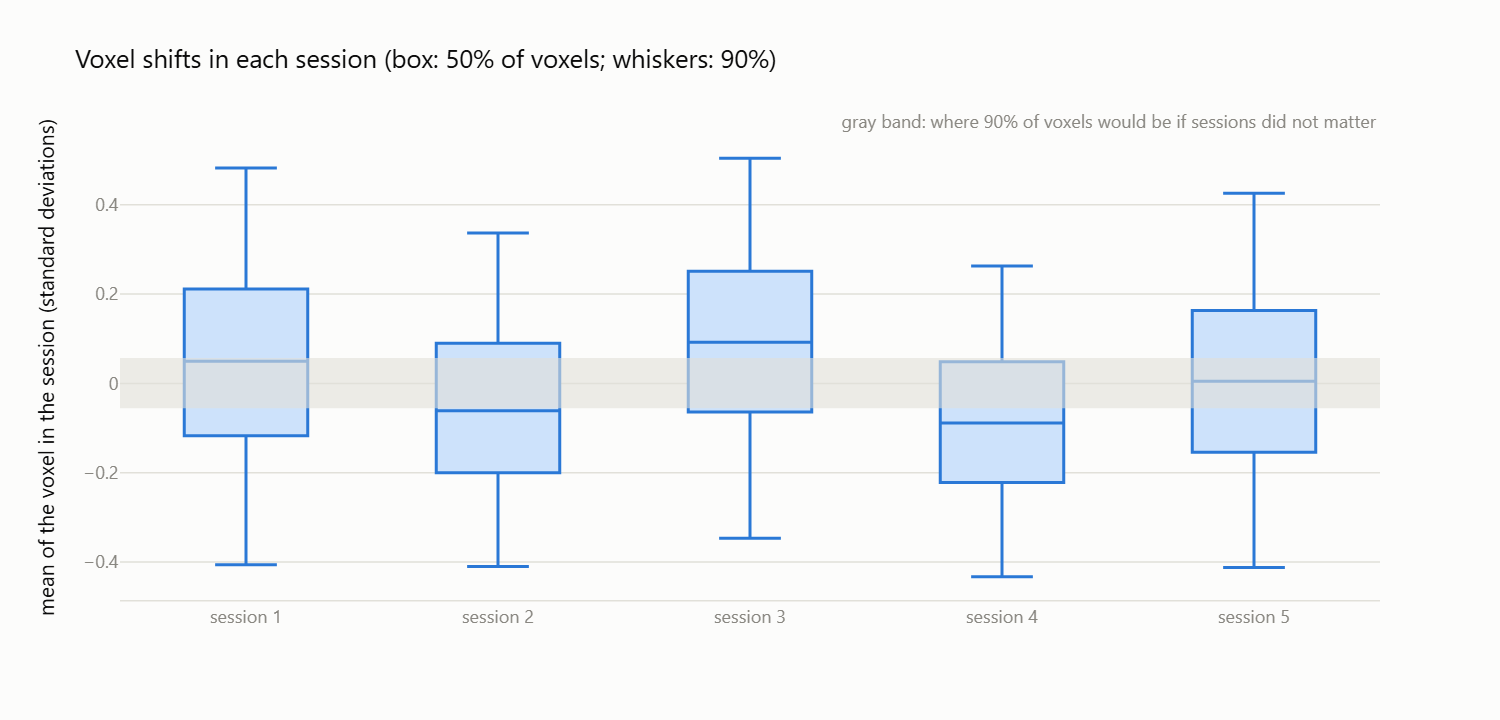

In [34]:
# [3.4.3] Chart: voxel shifts by session
quantiles = np.percentile(session_shift, [5, 25, 50, 75, 95], axis=1)
chance_low, chance_high = np.percentile(chance_shift, [5, 95])

fig = go.Figure()
fig.add_hrect(y0=chance_low, y1=chance_high, fillcolor=GRID, opacity=0.6, line_width=0)
fig.add_box(
    x=[f"session {s}" for s in SESSIONS],
    lowerfence=quantiles[0], q1=quantiles[1], median=quantiles[2], q3=quantiles[3], upperfence=quantiles[4],
    marker=dict(color=BLUE), line=dict(color=BLUE, width=2), fillcolor="#cde2fb",
    hoverinfo="y", showlegend=False,
)
fig.add_annotation(x=1.0, xref="paper", xanchor="right", y=1.0, yref="paper", yanchor="bottom", showarrow=False,
                   text="gray band: where 90% of voxels would be if sessions did not matter",
                   font=dict(color=MUTED, size=12))

style(fig,
      title="Voxel shifts in each session (box: 50% of voxels; whiskers: 90%)",
      xaxis_title="",
      yaxis_title="mean of the voxel in the session (standard deviations)")
fig.update_layout(height=480)
fig.show()

In [35]:
# [3.4.4] Two ways to standardize: global and per session
X_z_global = X_z

per_session = X.reshape(len(SESSIONS), TRIALS_PER_SESSION, -1)
X_z_session = ((per_session - per_session.mean(axis=1, keepdims=True))
               / per_session.std(axis=1, keepdims=True)).reshape(X.shape)

print("Largest shift of a voxel in each session (standard deviations):")
pd.DataFrame({
    "global z-score": np.abs(X_z_global.reshape(per_session.shape).mean(axis=1)).max(axis=1),
    "per-session z-score": np.abs(X_z_session.reshape(per_session.shape).mean(axis=1)).max(axis=1),
}, index=pd.Index(SESSIONS, name="session")).round(3)

Largest shift of a voxel in each session (standard deviations):


,global z-score,per-session z-score
session,,
1,1.233,0.0
2,1.228,0.0
3,1.324,0.0
4,1.273,0.0
5,1.343,0.0


## 5. Voxel quality

NSD publishes two quality measures per voxel, computed by the NSD authors on **all** sessions of the subject:

- **`R2`**: percent of the raw signal of the voxel explained by the regression that produced the betas (0–100).
- **`ncsnr`** (noise-ceiling signal-to-noise ratio): how much the response of the voxel varies **between different images** (signal) relative to how much it varies **between repetitions of the same image** (noise). 1 means signal equal to noise; 0 means only noise.

From `ncsnr`, the NSD documentation defines the **noise ceiling**, the percent of a voxel's variance that is due to the image, for a response averaged over `n` repetitions:

$$\text{noise ceiling} = 100 \cdot \frac{\text{ncsnr}^2}{\text{ncsnr}^2 + 1/n}$$

In [36]:
# [3.5.3] Noise ceiling for 1, 2 and 3 repetitions
# Load the two quality measures
ncsnr = nib.load(BETAS_DIR / "ncsnr.nii.gz").get_fdata()[mask]
r2 = nib.load(BETAS_DIR / "R2.nii.gz").get_fdata()[mask]

print(f"Correlation between ncsnr and R2 over the {len(ncsnr)} voxels: {np.corrcoef(ncsnr, r2)[0, 1]:.2f}")

pd.DataFrame({
    "ncsnr": pd.Series(ncsnr).describe(),
    "R2 (%)": pd.Series(r2).describe(),
}).round(2)

def noise_ceiling(ncsnr_values, n):
    return 100 * ncsnr_values**2 / (ncsnr_values**2 + 1 / n)

noise_table = pd.DataFrame({
    f"{n} repetition{'s' if n > 1 else ''}": pd.Series(noise_ceiling(ncsnr, n)).describe()[["mean", "25%", "50%", "75%"]]
    for n in [1, 2, 3]
})
noise_table.rename(index={"50%": "median"}).round(1)

Correlation between ncsnr and R2 over the 15724 voxels: 0.75


,1 repetition,2 repetitions,3 repetitions
mean,14.3,23.3,29.9
25%,4.7,9.0,12.9
median,11.5,20.7,28.1
75%,21.1,34.8,44.5


## 6. Repetitions of the same image

The most direct check of the data: if betas carry information about the image, two viewings of the **same** image must be more similar than two viewings of **different** images.

"Similar" = the correlation between the two vectors of 15,724 voxels, the same idea as the similarity between two embeddings.

We build four kinds of trial pairs:

| | same session | different sessions |
|---|---|---|
| **same image** | repetitions on the same day | repetitions on different days |
| **different images** | random pairs | random pairs |

In [37]:
# [3.6.2] Correlation of every pair, with both standardizations
# Build the pairs of trials
rows = trials.reset_index().rename(columns={"index": "row"})   # row = position in X

# All pairs of trials of the same image
same_pairs = pd.DataFrame(
    [pair for _, group in rows.groupby("nsdId")["row"] if len(group) > 1
     for pair in combinations(group, 2)],
    columns=["a", "b"],
)

# Random pairs of different images
rng = np.random.default_rng(0)
candidates = pd.DataFrame({"a": rng.integers(0, len(rows), 40000), "b": rng.integers(0, len(rows), 40000)})
different = rows["nsdId"].to_numpy()[candidates["a"]] != rows["nsdId"].to_numpy()[candidates["b"]]
diff_pairs = candidates[different].copy()

session_of = rows["session"].to_numpy()
for pairs in (same_pairs, diff_pairs):
    pairs["session"] = np.where(session_of[pairs["a"]] == session_of[pairs["b"]],
                                "same session", "different sessions")

same_pairs["image"] = "same image"
diff_pairs["image"] = "different images"
pairs = pd.concat([same_pairs, diff_pairs], ignore_index=True)

pd.crosstab(pairs["image"], pairs["session"])

def pair_correlation(data, a, b):
    # Pearson correlation between rows a and b of the matrix (over the 15,724 voxels)
    standardized = (data - data.mean(axis=1, keepdims=True)) / data.std(axis=1, keepdims=True)
    return (standardized[a] * standardized[b]).mean(axis=1)

pairs["r, global z-score"] = pair_correlation(X_z_global, pairs["a"].to_numpy(), pairs["b"].to_numpy())
pairs["r, per-session z-score"] = pair_correlation(X_z_session, pairs["a"].to_numpy(), pairs["b"].to_numpy())

pairs.groupby(["image", "session"])[["r, global z-score", "r, per-session z-score"]].mean().round(3)

r, global z-score  r, per-session z-score
image            session                                                      
different images different sessions             -0.017                   0.000
                 same session                    0.066                  -0.001
same image       different sessions              0.128                   0.153
                 same session                    0.218                   0.160

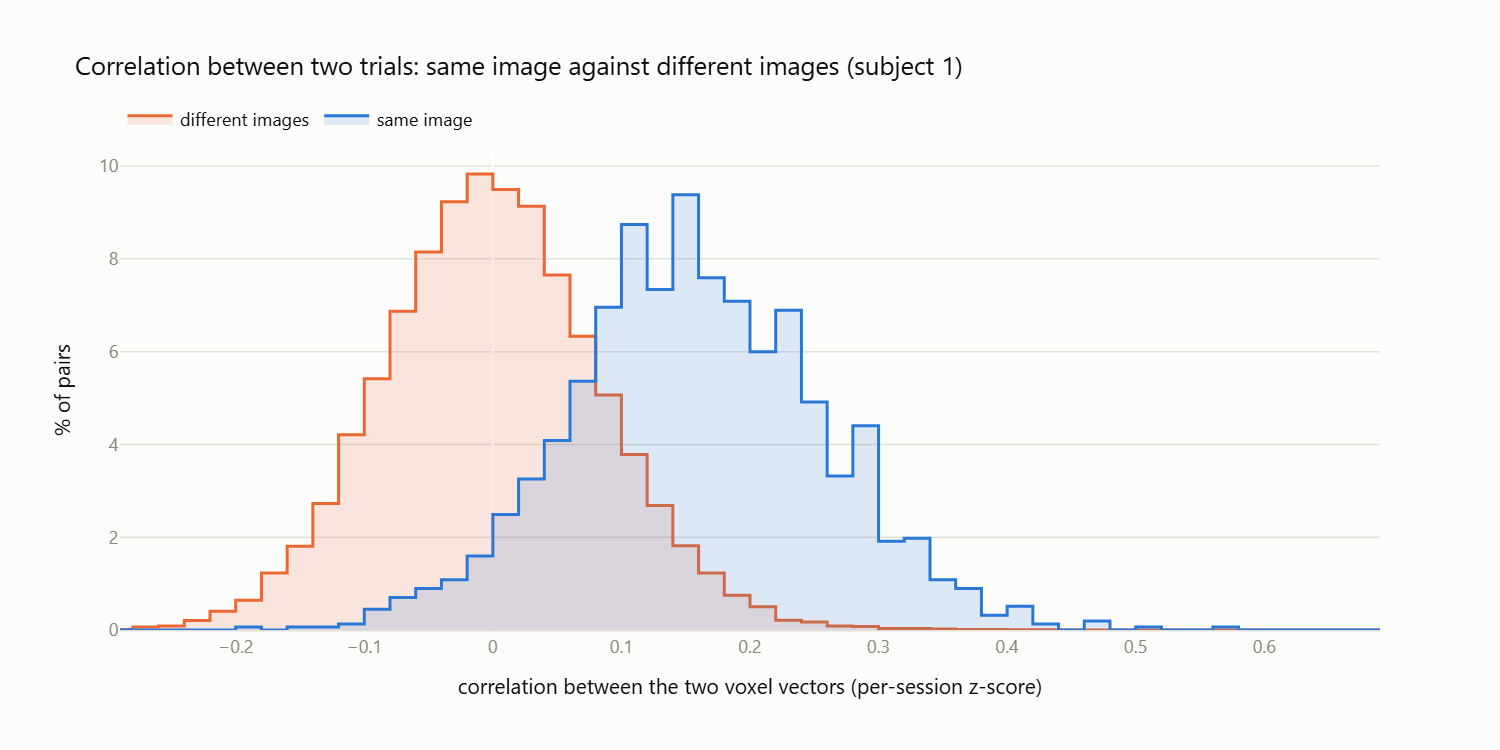

In [38]:
# [3.6.3] Chart: same image against different images
edges = np.arange(-0.3, 0.72, 0.02)
centers = (edges[:-1] + edges[1:]) / 2
column = "r, per-session z-score"

fig = go.Figure()
for label, color, fill in [("different images", ORANGE, "rgba(235,104,52,0.15)"),
                           ("same image", BLUE, "rgba(42,120,214,0.15)")]:
    values = pairs.loc[pairs["image"] == label, column]
    hist, _ = np.histogram(values, bins=edges)
    fig.add_scatter(
        x=centers, y=hist / hist.sum() * 100, mode="lines", name=label,
        line=dict(color=color, width=2, shape="hvh"), fill="tozeroy", fillcolor=fill,
        hovertemplate=label + ", r ≈ %{x:.2f}: %{y:.1f}% of pairs<extra></extra>",
    )

style(fig,
      title="Correlation between two trials: same image against different images (subject 1)",
      xaxis_title="correlation between the two voxel vectors (per-session z-score)",
      yaxis_title="% of pairs")
fig.update_layout(margin=dict(t=100))
fig.show()

In [39]:
# [3.6.4] One number: how often the same image wins
def separation(column, session_kind):
    subset = pairs[pairs["session"] == session_kind]
    same = subset.loc[subset["image"] == "same image", column].to_numpy()
    diff = subset.loc[subset["image"] == "different images", column].to_numpy()
    draws = np.random.default_rng(0)
    return (draws.choice(same, 200000) > draws.choice(diff, 200000)).mean() * 100


pd.DataFrame({
    session_kind: {
        "global z-score": separation("r, global z-score", session_kind),
        "per-session z-score": separation("r, per-session z-score", session_kind),
    }
    for session_kind in ["same session", "different sessions"]
}).round(1)

,same session,different sessions
global z-score,86.9,90.3
per-session z-score,87.6,90.5
